# Assignment Beta, Q2: LoRA vs QLoRA vs DoRA vs AdaLoRA
Base model: Qwen2.5-1.5B-Instruct. Data: glaive-function-calling-v2 (2,000 examples, 1,800 train / 200 test).

Colab setup: Runtime > Change runtime type > **T4 GPU**. Run the cells top to bottom.
Run the cells in order. Every finished run is saved to `/kaggle/working/results.json`, so if the session dies you can re-run and finished runs are skipped.

In [1]:
from google.colab import drive
drive.mount("/content/drive")
!mkdir -p /kaggle /content/drive/MyDrive/q2
!ln -sfn /content/drive/MyDrive/q2 /kaggle/working
import os, glob, shutil
# first time only: move the old run-1 files into a safe place (safe to re-run after a disconnect)
if os.path.exists("/kaggle/working/results.json") and not os.path.exists("/kaggle/working/results_run1.json"):
    shutil.move("/kaggle/working/results.json", "/kaggle/working/results_run1.json")
    os.makedirs("/kaggle/working/run1", exist_ok=True)
    for f in glob.glob("/kaggle/working/outputs_*.json"):
        shutil.move(f, "/kaggle/working/run1/")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
!pip install -q -U peft bitsandbytes accelerate

In [3]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [4]:
import os, re, json, time, random, gc
import numpy as np, torch
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig, get_linear_schedule_with_warmup
from peft import LoraConfig, AdaLoraConfig, get_peft_model

MODEL = "Qwen/Qwen2.5-1.5B-Instruct"
SEED, EPOCHS, BATCH, LR, MAX_NEW = 42, 1, 2, 2e-4, 128   # same for every run (batch 2 fits the free T4)
TARGETS = ["q_proj", "k_proj", "v_proj", "o_proj"]        # same target modules for every run
RESULTS = "/kaggle/working/results.json"
results = json.load(open(RESULTS)) if os.path.exists(RESULTS) else {}

tok = AutoTokenizer.from_pretrained(MODEL)
print("gpu:", torch.cuda.get_device_name(0))

gpu: Tesla T4


## 1. Data (turn glaive chats into clean JSON targets)

In [5]:
USE_RULE = False   # False = the model is NOT told to answer in JSON, so the 'before' picture means something
RULE_TEXT = '\n\nIf a function is needed, reply with ONLY a JSON object like {"name": "...", "arguments": {...}} and nothing else.'

def make_prompt(system, user):
    msgs = [{"role": "system", "content": system}, {"role": "user", "content": user}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

def parse(row):
    # keep only chats where the first assistant turn is a function call
    parts = row["chat"].split("ASSISTANT:")
    if len(parts) < 2 or not parts[1].strip().startswith("<functioncall>"):
        return None
    user = parts[0].replace("USER:", "", 1).strip()
    call = parts[1].split("<|endoftext|>")[0].replace("<functioncall>", "").strip()
    name = re.search(r'"name":\s*"([^"]+)"', call)
    args = re.search(r'"arguments":\s*\'(.*)\'\s*}', call, re.S)
    if not name or not args:
        return None
    try:
        arguments = json.loads(args.group(1))
    except Exception:
        return None
    if not isinstance(arguments, dict):
        return None
    system = row["system"].replace("SYSTEM:", "", 1).strip()
    if USE_RULE:
        system += RULE_TEXT
    target = json.dumps({"name": name.group(1), "arguments": arguments})
    return {"user": user, "system": system, "prompt": make_prompt(system, user), "target": target,
            "name": name.group(1), "arguments": arguments}

raw = load_dataset("glaiveai/glaive-function-calling-v2", split="train").shuffle(seed=SEED)
data = []
for row in raw:
    ex = parse(row)
    if ex is None:
        continue
    if len(tok(ex["prompt"] + ex["target"]).input_ids) > 700:   # skip very long ones
        continue
    data.append(ex)
    if len(data) == 2000:
        break

train, test = data[:1800], data[1800:]      # last 200 = test set, never used in training
print(len(train), len(test))
print(test[0]["user"]); print(test[0]["target"])

1800 200
Hi, I need to convert 1000 USD to EUR. Can you help me with that?
{"name": "convert_currency", "arguments": {"amount": 1000, "from_currency": "USD", "to_currency": "EUR"}}


## 2. Training and evaluation code (same for all methods)

In [6]:
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def encode(ex):
    p = tok(ex["prompt"], add_special_tokens=False).input_ids
    t = tok(ex["target"] + tok.eos_token, add_special_tokens=False).input_ids
    return p + t, [-100] * len(p) + t        # loss only on the answer part

def batches(examples, seed):
    idx = list(range(len(examples)))
    random.Random(seed).shuffle(idx)
    for i in range(0, len(idx), BATCH):
        enc = [encode(examples[j]) for j in idx[i:i + BATCH]]
        L = max(len(a) for a, _ in enc)
        ids = [a + [tok.pad_token_id] * (L - len(a)) for a, _ in enc]
        lab = [b + [-100] * (L - len(b)) for _, b in enc]
        att = [[1] * len(a) + [0] * (L - len(a)) for a, _ in enc]
        yield [torch.tensor(x).cuda() for x in (ids, att, lab)]

def load_model(method):
    if method == "qlora":
        bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                 bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True)
        model = AutoModelForCausalLM.from_pretrained(MODEL, quantization_config=bnb, device_map={"": 0})
    else:
        model = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float16, device_map={"": 0})
    if method != "base":
        model.gradient_checkpointing_enable()    # all 4 methods use it, so memory is comparable
        model.enable_input_require_grads()       # needed so gradients reach the adapters with checkpointing
    return model

def total_steps():
    return EPOCHS * ((len(train) + BATCH - 1) // BATCH)

def add_adapter(model, method, r):
    if method == "adalora":
        cfg = AdaLoraConfig(init_r=int(r * 1.5), target_r=r, lora_alpha=2 * r, target_modules=TARGETS,
                            tinit=100, tfinal=200, deltaT=10, total_step=total_steps(),
                            lora_dropout=0.05, task_type="CAUSAL_LM")
    else:
        cfg = LoraConfig(r=r, lora_alpha=2 * r, target_modules=TARGETS, lora_dropout=0.05,
                         use_dora=(method == "dora"), task_type="CAUSAL_LM")
    model = get_peft_model(model, cfg)
    for p in model.parameters():             # adapter weights in fp32 so the fp16 grad scaler works
        if p.requires_grad:
            p.data = p.data.float()
    return model

def train_model(model, method):
    STEPS = total_steps()
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=LR, weight_decay=0.0)
    sched = get_linear_schedule_with_warmup(opt, int(0.05 * STEPS), STEPS)
    scaler = torch.amp.GradScaler("cuda")
    model.train()
    step = 0
    for ep in range(EPOCHS):
        for ids, att, lab in batches(train, SEED + ep):
            with torch.autocast("cuda", dtype=torch.float16):
                loss = model(input_ids=ids, attention_mask=att, labels=lab).loss
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            if method == "adalora":
                model.base_model.update_and_allocate(step)   # AdaLoRA moves rank budget here
            opt.zero_grad()
            step += 1
            if step % 50 == 0:
                print(step, "/", STEPS, "loss", round(loss.item(), 4))

def get_call(text):
    try:
        return json.loads(text)
    except Exception:
        pass
    a, b = text.find("{"), text.rfind("}")
    if a != -1 and b > a:
        try:
            return json.loads(text[a:b + 1])
        except Exception:
            pass
    return None

def evaluate(model):
    model.eval()
    tok.padding_side = "left"
    outs = []
    t0 = time.time()
    for i in range(0, len(test), 8):
        chunk = test[i:i + 8]
        enc = tok([e["prompt"] for e in chunk], return_tensors="pt", padding=True, add_special_tokens=False).to("cuda")
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
            gen = model.generate(**enc, max_new_tokens=MAX_NEW, do_sample=False, pad_token_id=tok.pad_token_id)
        outs += tok.batch_decode(gen[:, enc.input_ids.shape[1]:], skip_special_tokens=True)
    gen_time = time.time() - t0
    valid = tool = full = 0
    rows = []
    for e, o in zip(test, outs):
        try:
            json.loads(o.strip()); valid += 1          # strict: extra text around the JSON = invalid
        except Exception:
            pass
        c = get_call(o)                                # lenient: find the call even with extra text
        ok_tool = isinstance(c, dict) and c.get("name") == e["name"]
        ok_full = ok_tool and c.get("arguments") == e["arguments"]
        tool += int(ok_tool); full += int(ok_full)
        rows.append({"user": e["user"], "gold": e["target"], "output": o,
                     "tool_ok": bool(ok_tool), "full_ok": bool(ok_full)})
    return valid, tool, full, gen_time, rows

def run(method, r=8, tag=None):
    tag = tag or f"{method}_r{r}"
    if tag in results:
        print("already done:", tag); return
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    set_seed(SEED)
    model = load_model(method)
    weights_gb = torch.cuda.memory_allocated() / 1024 ** 3     # memory used by the loaded model alone
    if method == "base":
        trainable, total, mins = 0, sum(p.numel() for p in model.parameters()), 0.0
    else:
        model = add_adapter(model, method, r)
        trainable, total = model.get_nb_trainable_parameters()
        t0 = time.time()
        train_model(model, method)
        mins = (time.time() - t0) / 60
    peak = torch.cuda.max_memory_allocated() / 1024 ** 3     # training peak (weights + training)
    valid, tool, full, gen_time, rows = evaluate(model)
    results[tag] = {"trainable": trainable, "total": total, "trainable_pct": round(100 * trainable / total, 3),
                    "weights_gb": round(weights_gb, 2), "peak_gb": round(peak, 2), "train_min": round(mins, 1),
                    "json_valid": valid, "tool_correct": tool, "full_match": full,
                    "gen_seconds_200": round(gen_time, 1)}
    json.dump(results, open(RESULTS, "w"), indent=1)
    json.dump(rows, open(f"/kaggle/working/outputs_{tag}.json", "w"), indent=1)
    print(tag, results[tag])
    del model; gc.collect(); torch.cuda.empty_cache()

## 3. Part B: the five rows (run one cell at a time)

In [7]:
run("base", tag="base")      # before picture: no fine-tuning, NOT told to answer in JSON (peak_gb here is inference only)

already done: base


In [7]:
# extra row: base model with the JSON instruction added to the prompt (a prompt-only baseline)
test_plain = test
test = [dict(e, prompt=make_prompt(e["system"] + RULE_TEXT, e["user"])) for e in test_plain]
run("base", tag="base_with_instruction")
test = test_plain

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

base_with_instruction {'trainable': 0, 'total': 1543714304, 'trainable_pct': 0.0, 'weights_gb': 2.88, 'peak_gb': 2.88, 'train_min': 0.0, 'json_valid': 200, 'tool_correct': 200, 'full_match': 190, 'gen_seconds_200': 54.2}


In [8]:
run("lora")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


50 / 900 loss 0.0009
100 / 900 loss 0.0002
150 / 900 loss 0.0008
200 / 900 loss 0.0719
250 / 900 loss 0.0603
300 / 900 loss 0.0108
350 / 900 loss 0.0
400 / 900 loss 0.0
450 / 900 loss 0.0005
500 / 900 loss 0.0007
550 / 900 loss 0.0012
600 / 900 loss 0.0008
650 / 900 loss 0.0002
700 / 900 loss 0.0061
750 / 900 loss 0.0013
800 / 900 loss 0.0001
850 / 900 loss 0.0001
900 / 900 loss 0.0716
lora_r8 {'trainable': 2179072, 'total': 1545893376, 'trainable_pct': 0.141, 'weights_gb': 2.88, 'peak_gb': 4.7, 'train_min': 5.9, 'json_valid': 200, 'tool_correct': 200, 'full_match': 188, 'gen_seconds_200': 79.8}


In [9]:
run("qlora")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

50 / 900 loss 0.0047
100 / 900 loss 0.0003
150 / 900 loss 0.0004
200 / 900 loss 0.0522
250 / 900 loss 0.0586
300 / 900 loss 0.0052
350 / 900 loss 0.0006
400 / 900 loss 0.0002
450 / 900 loss 0.0008
500 / 900 loss 0.0035
550 / 900 loss 0.0005
600 / 900 loss 0.0007
650 / 900 loss 0.0005
700 / 900 loss 0.0054
750 / 900 loss 0.0023
800 / 900 loss 0.0001
850 / 900 loss 0.0001
900 / 900 loss 0.0953
qlora_r8 {'trainable': 2179072, 'total': 1545893376, 'trainable_pct': 0.141, 'weights_gb': 1.09, 'peak_gb': 3.41, 'train_min': 8.2, 'json_valid': 200, 'tool_correct': 200, 'full_match': 189, 'gen_seconds_200': 118.6}


In [10]:
run("dora")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

50 / 900 loss 0.001
100 / 900 loss 0.0002
150 / 900 loss 0.0007
200 / 900 loss 0.0722
250 / 900 loss 0.0606
300 / 900 loss 0.0106
350 / 900 loss 0.0
400 / 900 loss 0.0
450 / 900 loss 0.0005
500 / 900 loss 0.0008
550 / 900 loss 0.0012
600 / 900 loss 0.0008
650 / 900 loss 0.0002
700 / 900 loss 0.0059
750 / 900 loss 0.0013
800 / 900 loss 0.0001
850 / 900 loss 0.0001
900 / 900 loss 0.0712
dora_r8 {'trainable': 2279424, 'total': 1545993728, 'trainable_pct': 0.147, 'weights_gb': 2.89, 'peak_gb': 4.7, 'train_min': 8.6, 'json_valid': 200, 'tool_correct': 200, 'full_match': 188, 'gen_seconds_200': 134.8}


In [11]:
run("adalora")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

50 / 900 loss 1.2906
100 / 900 loss 0.3528
150 / 900 loss 0.27
200 / 900 loss 0.2824
250 / 900 loss 0.2036
300 / 900 loss 0.1071
350 / 900 loss 0.06
400 / 900 loss 0.0431
450 / 900 loss 0.0288
500 / 900 loss 0.0193
550 / 900 loss 0.0129
600 / 900 loss 0.0104
650 / 900 loss 0.0079
700 / 900 loss 0.2507
750 / 900 loss 0.0068
800 / 900 loss 0.0056
850 / 900 loss 0.0053
900 / 900 loss 0.0586
adalora_r8 {'trainable': 3270064, 'total': 1546984368, 'trainable_pct': 0.211, 'weights_gb': 2.89, 'peak_gb': 4.76, 'train_min': 9.0, 'json_valid': 200, 'tool_correct': 200, 'full_match': 189, 'gen_seconds_200': 89.6}


In [12]:
import pandas as pd
df = pd.DataFrame(results).T
df

,trainable,total,trainable_pct,weights_gb,peak_gb,train_min,json_valid,tool_correct,full_match,gen_seconds_200
base,0.0,1.543714e+09,0.000,2.88,2.88,0.0,0.0,0.0,0.0,149.4
base_with_instruction,0.0,1.543714e+09,0.000,2.88,2.88,0.0,200.0,200.0,190.0,54.2
lora_r8,2179072.0,1.545893e+09,0.141,2.88,4.70,5.9,200.0,200.0,188.0,79.8
qlora_r8,2179072.0,1.545893e+09,0.141,1.09,3.41,8.2,200.0,200.0,189.0,118.6
dora_r8,2279424.0,1.545994e+09,0.147,2.89,4.70,8.6,200.0,200.0,188.0,134.8
adalora_r8,3270064.0,1.546984e+09,0.211,2.89,4.76,9.0,200.0,200.0,189.0,89.6


## 4. Part C: rank sweep for the winning method
Set BEST to the method with the best tool accuracy above (r=8 is already done).

In [13]:
BEST = "lora"      # the method you pick from the table above ("lora", "qlora", "dora" or "adalora")
for r in [4, 16, 32]:
    run(BEST, r)

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

50 / 900 loss 0.001
100 / 900 loss 0.0003
150 / 900 loss 0.0009
200 / 900 loss 0.0698
250 / 900 loss 0.0615
300 / 900 loss 0.0101
350 / 900 loss 0.0001
400 / 900 loss 0.0
450 / 900 loss 0.0006
500 / 900 loss 0.0007
550 / 900 loss 0.0006
600 / 900 loss 0.0008
650 / 900 loss 0.0002
700 / 900 loss 0.0068
750 / 900 loss 0.0012
800 / 900 loss 0.0001
850 / 900 loss 0.0001
900 / 900 loss 0.0751
lora_r4 {'trainable': 1089536, 'total': 1544803840, 'trainable_pct': 0.071, 'weights_gb': 2.89, 'peak_gb': 4.69, 'train_min': 5.8, 'json_valid': 200, 'tool_correct': 200, 'full_match': 187, 'gen_seconds_200': 79.4}


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

50 / 900 loss 0.0011
100 / 900 loss 0.0001
150 / 900 loss 0.0004
200 / 900 loss 0.0661
250 / 900 loss 0.0565
300 / 900 loss 0.009
350 / 900 loss 0.0
400 / 900 loss 0.0
450 / 900 loss 0.0007
500 / 900 loss 0.0013
550 / 900 loss 0.0007
600 / 900 loss 0.0005
650 / 900 loss 0.0002
700 / 900 loss 0.0042
750 / 900 loss 0.0015
800 / 900 loss 0.0001
850 / 900 loss 0.0001
900 / 900 loss 0.0744
lora_r16 {'trainable': 4358144, 'total': 1548072448, 'trainable_pct': 0.282, 'weights_gb': 2.89, 'peak_gb': 4.72, 'train_min': 5.8, 'json_valid': 200, 'tool_correct': 200, 'full_match': 190, 'gen_seconds_200': 80.1}


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

50 / 900 loss 0.0014
100 / 900 loss 0.0001
150 / 900 loss 0.0004
200 / 900 loss 0.0671
250 / 900 loss 0.0539
300 / 900 loss 0.0065
350 / 900 loss 0.0
400 / 900 loss 0.0
450 / 900 loss 0.0007
500 / 900 loss 0.0007
550 / 900 loss 0.0005
600 / 900 loss 0.0005
650 / 900 loss 0.0003
700 / 900 loss 0.0036
750 / 900 loss 0.0015
800 / 900 loss 0.0001
850 / 900 loss 0.0
900 / 900 loss 0.0835
lora_r32 {'trainable': 8716288, 'total': 1552430592, 'trainable_pct': 0.561, 'weights_gb': 2.89, 'peak_gb': 4.77, 'train_min': 5.8, 'json_valid': 200, 'tool_correct': 200, 'full_match': 191, 'gen_seconds_200': 79.2}


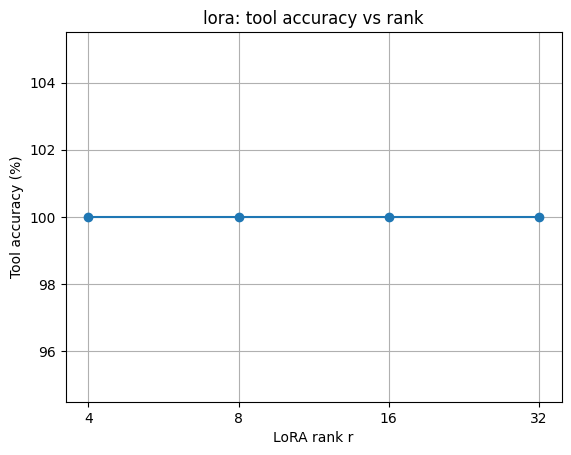

4 100.0 4.69 GB 5.8 min
8 100.0 4.7 GB 5.9 min
16 100.0 4.72 GB 5.8 min
32 100.0 4.77 GB 5.8 min


In [14]:
import matplotlib.pyplot as plt
ranks = [4, 8, 16, 32]
acc = [100 * results[f"{BEST}_r{r}"]["tool_correct"] / 200 for r in ranks]
plt.plot(ranks, acc, marker="o")
plt.xscale("log", base=2); plt.xticks(ranks, ranks)
plt.xlabel("LoRA rank r"); plt.ylabel("Tool accuracy (%)"); plt.title(f"{BEST}: tool accuracy vs rank")
plt.grid(True); plt.savefig("/kaggle/working/rank_vs_accuracy.png", dpi=150); plt.show()
for r, a in zip(ranks, acc):
    print(r, a, results[f"{BEST}_r{r}"]["peak_gb"], "GB", results[f"{BEST}_r{r}"]["train_min"], "min")

## 5. Report helper: examples the best model still gets wrong

In [15]:
rows = json.load(open(f"/kaggle/working/outputs_{BEST}_r8.json"))
wrong = [x for x in rows if not x["full_ok"]]
print(len(wrong), "wrong out of 200")
for x in wrong[:5]:
    print("CUSTOMER:", x["user"]); print("GOLD:", x["gold"]); print("MODEL:", x["output"]); print("-" * 40)

12 wrong out of 200
CUSTOMER: I am looking for movies with Tom Hanks.
GOLD: {"name": "search_movies", "arguments": {"keyword": "Tom Hanks"}}
MODEL: {"name": "search_movies", "arguments": {"actors": ["Tom Hanks"]}}
----------------------------------------
CUSTOMER: I want to create an event for my birthday party. It's on 25th of next month from 7pm to 10pm. The party will be at my house.
GOLD: {"name": "create_event", "arguments": {"title": "My Birthday Party", "start_time": "2022-05-25T19:00:00", "end_time": "2022-05-25T22:00:00", "location": "My house"}}
MODEL: {"name": "create_event", "arguments": {"title": "Birthday Party", "start_time": "2023-04-25T19:00:00Z", "end_time": "2023-04-25T23:00:00Z", "location": "My House"}}
----------------------------------------
CUSTOMER: I'm looking for a quick Italian recipe that uses chicken and tomatoes.
GOLD: {"name": "search_recipes", "arguments": {"ingredients": ["chicken", "tomatoes"], "cuisine": "Italian", "max_prep_time": 30}}
MODEL: {"name

In [16]:
# what does the base model (no instruction) actually write?
rows = json.load(open("/kaggle/working/outputs_base.json"))
for x in rows[:3]:
    print("MODEL:", x["output"][:300]); print("-" * 30)

# full results table, including the rank sweep
import pandas as pd
pd.DataFrame(results).T

MODEL: Of course! To convert 1000 USD to EUR using the available function, I will use the `convert_currency` function and provide it with the necessary parameters.

Here's how we can do it:

```python
result = convert_currency(amount=1000, from_currency="USD", to_currency="EUR")
print(result)
```

This cod
------------------------------
MODEL: Sure, I can help you with that. Here's how you can execute the program:

```json
{
  "program_name": "DataAnalysis",
  "arguments": ["file1.csv", "file2.csv", "file3.csv"]
}
```

Just send this JSON object to me using the function `execute_program`, and I will run your program for you.
------------------------------
MODEL: I don't have direct access to real-time financial data like stock prices. However, I can help you get this information by using my function `get_stock_price`. Please provide me with the stock symbol for Apple (AAPL).
------------------------------


,trainable,total,trainable_pct,weights_gb,peak_gb,train_min,json_valid,tool_correct,full_match,gen_seconds_200
base,0.0,1.543714e+09,0.000,2.88,2.88,0.0,0.0,0.0,0.0,149.4
base_with_instruction,0.0,1.543714e+09,0.000,2.88,2.88,0.0,200.0,200.0,190.0,54.2
lora_r8,2179072.0,1.545893e+09,0.141,2.88,4.70,5.9,200.0,200.0,188.0,79.8
qlora_r8,2179072.0,1.545893e+09,0.141,1.09,3.41,8.2,200.0,200.0,189.0,118.6
dora_r8,2279424.0,1.545994e+09,0.147,2.89,4.70,8.6,200.0,200.0,188.0,134.8
adalora_r8,3270064.0,1.546984e+09,0.211,2.89,4.76,9.0,200.0,200.0,189.0,89.6
lora_r4,1089536.0,1.544804e+09,0.071,2.89,4.69,5.8,200.0,200.0,187.0,79.4
lora_r16,4358144.0,1.548072e+09,0.282,2.89,4.72,5.8,200.0,200.0,190.0,80.1
lora_r32,8716288.0,1.552431e+09,0.561,2.89,4.77,5.8,200.0,200.0,191.0,79.2
